# Baseline Ablation Report

This notebook is the presentation-friendly view of the current experiment sweep.

It now has four jobs:

- verify what the current data pipeline can and cannot ablate,
- load saved results for one chosen seed and compare `Cora` against `PubMed`,
- compare `Cora` across every available seed,
- inspect the saved configurations behind each result file.


In [1]:
from pathlib import Path
import json
import re

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
RESULTS_ROOT = PROJECT_ROOT / "results"

pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")


def _seed_from_path(path: Path) -> int:
    match = re.search(r"_seed(\d+)\.json$", path.name)
    if match is None:
        raise ValueError(f"Could not parse seed from result path: {path}")
    return int(match.group(1))


def load_results_frame(results_root: Path) -> pd.DataFrame:
    rows = []
    for path in sorted(results_root.glob("*/*_seed*.json")):
        payload = json.loads(path.read_text())
        rows.append(
            {
                "dataset": payload["dataset"],
                "method": payload["method"],
                "seed": int(payload.get("seed", _seed_from_path(path))),
                "test_roc_auc": payload["test"]["roc_auc"],
                "test_ap": payload["test"]["average_precision"],
                "val_roc_auc": payload["validation"]["roc_auc"],
                "val_ap": payload["validation"]["average_precision"],
                "params": payload["params"],
                "result_path": str(path.relative_to(PROJECT_ROOT)),
            }
        )

    if not rows:
        raise FileNotFoundError(f"No result JSON files found under {results_root}")

    results_df = pd.DataFrame(rows)
    return results_df.sort_values(["dataset", "seed", "test_roc_auc"], ascending=[True, True, False]).reset_index(drop=True)


all_results_df = load_results_frame(RESULTS_ROOT)

## 1. Confirm The Shared Graph Protocol

The current implementation uses one shared undirected benchmark protocol for all baselines.
Before comparing the feature-only pairwise baseline against graph-aware GNNs, we first confirm the graph representation exposed by the loader.

With the present `Planetoid` loader path, both `Cora` and `PubMed` arrive in the same undirected form used by the saved split artifacts and result JSONs.

In [2]:
from citegnn.data.loaders import load_citation_graph

graph_protocol_check = []
for dataset_name in ("Cora", "PubMed"):
    graph = load_citation_graph(dataset_name)
    graph_protocol_check.append(
        {
            "dataset": dataset_name,
            "is_undirected": graph.is_undirected,
            "edge_count": int(graph.edge_index.size(1)),
        }
    )

pd.DataFrame(graph_protocol_check)

,dataset,is_undirected,edge_count
0,Cora,True,10556
1,PubMed,True,88648


## 2. Compare `Cora` And `PubMed` For One Seed

Set `SELECTED_SEED` in the setup cell, then rerun from the top.
This section only loads result files whose filename matches that seed.

In [3]:
SELECTED_SEED = 42
seed_results_df = all_results_df[all_results_df["seed"] == SELECTED_SEED].copy()
if seed_results_df.empty:
    raise ValueError(f"No saved result JSONs found for seed {SELECTED_SEED}")

seed_results_df = seed_results_df.sort_values(["dataset", "test_roc_auc"], ascending=[True, False]).reset_index(drop=True)
seed_results_df

,dataset,method,seed,test_roc_auc,test_ap,val_roc_auc,val_ap,params,result_path
0,Cora,feature_only_mlp,42,0.822446,0.834283,0.821167,0.831876,"{'batch_size': 1024, 'best_epoch': 99, 'dropout': 0.2, 'epochs': 100, 'feature_mode': 'hadamard_abs_diff', 'hidden_d...",results\cora\feature_only_mlp_seed42.json
1,Cora,personalized_pagerank,42,0.794227,0.862788,0.794640,0.862048,"{'alpha': 0.85, 'split_seed': 42, 'train_graph_edges': 7392}",results\cora\personalized_pagerank_seed42.json
2,Cora,node2vec,42,0.687410,0.695194,0.685722,0.697231,"{'batch_size': 512, 'classifier_c': 1.0, 'context_window': 5, 'embedding_dim': 64, 'epochs': 3, 'learning_rate': 0.0...",results\cora\node2vec_seed42.json
3,Cora,gcn,42,0.673745,0.699162,0.679632,0.716425,"{'best_epoch': 2, 'decoder_hidden_dim': 64, 'dropout': 0.2, 'epochs': 50, 'hidden_dim': 64, 'learning_rate': 0.01, '...",results\cora\gcn_seed42.json
4,Cora,common_neighbors,42,0.671689,0.670884,0.664616,0.660692,"{'split_seed': 42, 'train_graph_edges': 7392}",results\cora\common_neighbors_seed42.json
5,Cora,adamic_adar,42,0.671638,0.670531,0.666067,0.669534,"{'split_seed': 42, 'train_graph_edges': 7392}",results\cora\adamic_adar_seed42.json
6,Cora,graphsage,42,0.539775,0.550494,0.521289,0.548854,"{'best_epoch': 2, 'decoder_hidden_dim': 64, 'dropout': 0.2, 'epochs': 50, 'hidden_dim': 64, 'learning_rate': 0.01, '...",results\cora\graphsage_seed42.json
7,PubMed,feature_only_mlp,42,0.934864,0.933232,0.937648,0.936826,"{'batch_size': 1024, 'best_epoch': 100, 'dropout': 0.2, 'epochs': 100, 'feature_mode': 'hadamard_abs_diff', 'hidden_...",results\pubmed\feature_only_mlp_seed42.json
8,PubMed,gcn,42,0.873617,0.847268,0.883183,0.858425,"{'best_epoch': 17, 'decoder_hidden_dim': 64, 'dropout': 0.2, 'epochs': 50, 'hidden_dim': 64, 'learning_rate': 0.01, ...",results\pubmed\gcn_seed42.json
9,PubMed,personalized_pagerank,42,0.813705,0.873070,0.813253,0.871878,"{'alpha': 0.85, 'split_seed': 42, 'train_graph_edges': 62056}",results\pubmed\personalized_pagerank_seed42.json


In [4]:
ranking_table = seed_results_df[["dataset", "method", "test_roc_auc", "test_ap"]].copy()
ranking_table["test_roc_auc"] = ranking_table["test_roc_auc"].map(lambda value: round(value, 4))
ranking_table["test_ap"] = ranking_table["test_ap"].map(lambda value: round(value, 4))
ranking_table

,dataset,method,test_roc_auc,test_ap
0,Cora,feature_only_mlp,0.8224,0.8343
1,Cora,personalized_pagerank,0.7942,0.8628
2,Cora,node2vec,0.6874,0.6952
3,Cora,gcn,0.6737,0.6992
4,Cora,common_neighbors,0.6717,0.6709
5,Cora,adamic_adar,0.6716,0.6705
6,Cora,graphsage,0.5398,0.5505
7,PubMed,feature_only_mlp,0.9349,0.9332
8,PubMed,gcn,0.8736,0.8473
9,PubMed,personalized_pagerank,0.8137,0.8731


In [5]:
pivot_auc = seed_results_df.pivot(index="method", columns="dataset", values="test_roc_auc").sort_index()
pivot_ap = seed_results_df.pivot(index="method", columns="dataset", values="test_ap").sort_index()

display(pivot_auc.style.format("{:.4f}"))
display(pivot_ap.style.format("{:.4f}"))

dataset,Cora,PubMed
method,,
adamic_adar,0.6716,0.6172
common_neighbors,0.6717,0.6172
feature_only_mlp,0.8224,0.9349
gcn,0.6737,0.8736
graphsage,0.5398,0.6649
node2vec,0.6874,0.6096
personalized_pagerank,0.7942,0.8137


dataset,Cora,PubMed
method,,
adamic_adar,0.6705,0.6174
common_neighbors,0.6709,0.6169
feature_only_mlp,0.8343,0.9332
gcn,0.6992,0.8473
graphsage,0.5505,0.6847
node2vec,0.6952,0.5514
personalized_pagerank,0.8628,0.8731


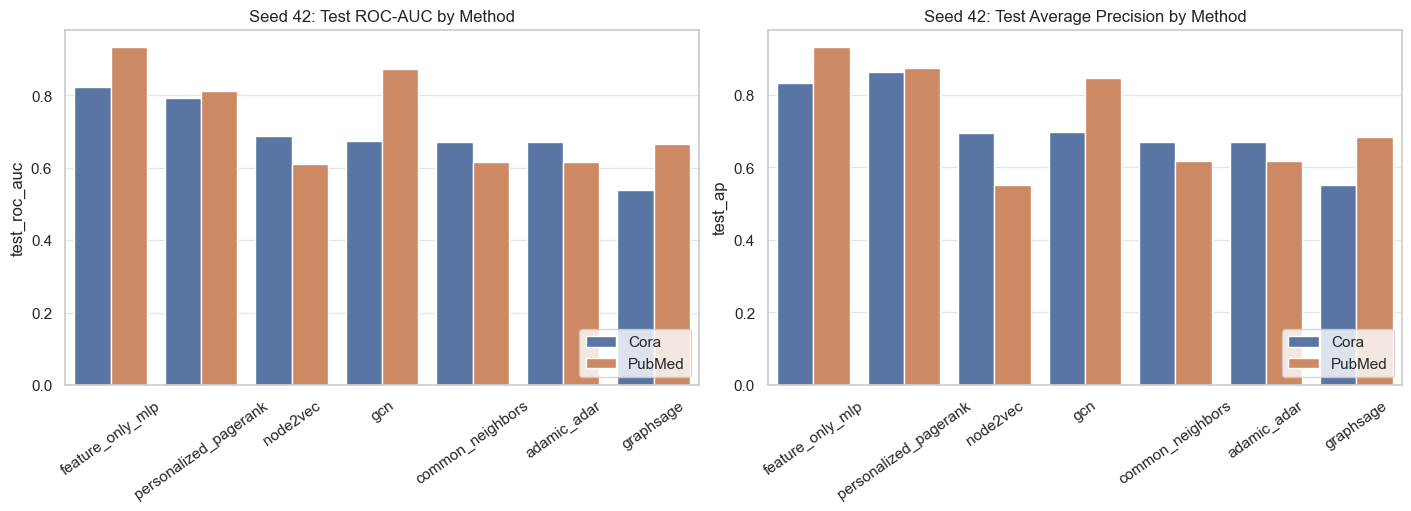

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

sns.barplot(
    data=seed_results_df,
    x="method",
    y="test_roc_auc",
    hue="dataset",
    ax=axes[0],
)
axes[0].set_title(f"Seed {SELECTED_SEED}: Test ROC-AUC by Method")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=35)

sns.barplot(
    data=seed_results_df,
    x="method",
    y="test_ap",
    hue="dataset",
    ax=axes[1],
)
axes[1].set_title(f"Seed {SELECTED_SEED}: Test Average Precision by Method")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=35)

for axis in axes:
    axis.legend(loc="lower right")

plt.show()

## 3. Compare `Cora` Across All Available Seeds

This section ignores `PubMed` and keeps every saved `Cora` result, so the comparison mirrors the dataset-comparison view above but uses `seed` as the grouping variable.

In [7]:
cora_all_seeds_df = all_results_df[all_results_df["dataset"] == "Cora"].copy()
if cora_all_seeds_df.empty:
    raise ValueError("No saved Cora result JSONs found")

cora_all_seeds_df = cora_all_seeds_df.sort_values(["seed", "test_roc_auc"], ascending=[True, False]).reset_index(drop=True)
cora_all_seeds_df

,dataset,method,seed,test_roc_auc,test_ap,val_roc_auc,val_ap,params,result_path
0,Cora,feature_only_mlp,7,0.848671,0.854752,0.804759,0.814901,"{'batch_size': 1024, 'best_epoch': 100, 'dropout': 0.2, 'epochs': 100, 'feature_mode': 'hadamard_abs_diff', 'hidden_...",results\cora\feature_only_mlp_seed7.json
1,Cora,personalized_pagerank,7,0.794373,0.864136,0.767752,0.847214,"{'alpha': 0.85, 'split_seed': 7, 'train_graph_edges': 7392}",results\cora\personalized_pagerank_seed7.json
2,Cora,gcn,7,0.706430,0.736385,0.671046,0.713690,"{'best_epoch': 9, 'decoder_hidden_dim': 64, 'dropout': 0.2, 'epochs': 50, 'hidden_dim': 64, 'learning_rate': 0.01, '...",results\cora\gcn_seed7.json
3,Cora,node2vec,7,0.702707,0.699571,0.704435,0.695445,"{'batch_size': 512, 'classifier_c': 1.0, 'context_window': 5, 'embedding_dim': 64, 'epochs': 3, 'learning_rate': 0.0...",results\cora\node2vec_seed7.json
4,Cora,adamic_adar,7,0.671537,0.673126,0.664471,0.664765,"{'split_seed': 7, 'train_graph_edges': 7392}",results\cora\adamic_adar_seed7.json
5,Cora,common_neighbors,7,0.670890,0.668966,0.664281,0.663140,"{'split_seed': 7, 'train_graph_edges': 7392}",results\cora\common_neighbors_seed7.json
6,Cora,graphsage,7,0.543559,0.568370,0.540298,0.565001,"{'best_epoch': 4, 'decoder_hidden_dim': 64, 'dropout': 0.2, 'epochs': 50, 'hidden_dim': 64, 'learning_rate': 0.01, '...",results\cora\graphsage_seed7.json
7,Cora,feature_only_mlp,13,0.824444,0.833060,0.822496,0.838888,"{'batch_size': 1024, 'best_epoch': 100, 'dropout': 0.2, 'epochs': 100, 'feature_mode': 'hadamard_abs_diff', 'hidden_...",results\cora\feature_only_mlp_seed13.json
8,Cora,personalized_pagerank,13,0.781288,0.856280,0.802469,0.868255,"{'alpha': 0.85, 'split_seed': 13, 'train_graph_edges': 7392}",results\cora\personalized_pagerank_seed13.json
9,Cora,gcn,13,0.681807,0.721390,0.682669,0.712475,"{'best_epoch': 8, 'decoder_hidden_dim': 64, 'dropout': 0.2, 'epochs': 50, 'hidden_dim': 64, 'learning_rate': 0.01, '...",results\cora\gcn_seed13.json


In [8]:
cora_seed_ranking = cora_all_seeds_df[["seed", "method", "test_roc_auc", "test_ap"]].copy()
cora_seed_ranking["test_roc_auc"] = cora_seed_ranking["test_roc_auc"].map(lambda value: round(value, 4))
cora_seed_ranking["test_ap"] = cora_seed_ranking["test_ap"].map(lambda value: round(value, 4))
cora_seed_ranking

,seed,method,test_roc_auc,test_ap
0,7,feature_only_mlp,0.8487,0.8548
1,7,personalized_pagerank,0.7944,0.8641
2,7,gcn,0.7064,0.7364
3,7,node2vec,0.7027,0.6996
4,7,adamic_adar,0.6715,0.6731
5,7,common_neighbors,0.6709,0.6690
6,7,graphsage,0.5436,0.5684
7,13,feature_only_mlp,0.8244,0.8331
8,13,personalized_pagerank,0.7813,0.8563
9,13,gcn,0.6818,0.7214


In [9]:
cora_pivot_auc = cora_all_seeds_df.pivot(index="method", columns="seed", values="test_roc_auc").sort_index(axis=1)
cora_pivot_ap = cora_all_seeds_df.pivot(index="method", columns="seed", values="test_ap").sort_index(axis=1)

display(cora_pivot_auc.style.format("{:.4f}"))
display(cora_pivot_ap.style.format("{:.4f}"))

seed,7,13,42,67
method,,,,
adamic_adar,0.6715,0.6636,0.6716,0.6643
common_neighbors,0.6709,0.6627,0.6717,0.6638
feature_only_mlp,0.8487,0.8244,0.8224,0.8204
gcn,0.7064,0.6818,0.6737,0.6893
graphsage,0.5436,0.5176,0.5398,0.5185
node2vec,0.7027,0.6764,0.6874,0.6610
personalized_pagerank,0.7944,0.7813,0.7942,0.7840


seed,7,13,42,67
method,,,,
adamic_adar,0.6731,0.6654,0.6705,0.6654
common_neighbors,0.6690,0.6598,0.6709,0.6623
feature_only_mlp,0.8548,0.8331,0.8343,0.8280
gcn,0.7364,0.7214,0.6992,0.7308
graphsage,0.5684,0.5434,0.5505,0.5357
node2vec,0.6996,0.6796,0.6952,0.6721
personalized_pagerank,0.8641,0.8563,0.8628,0.8578


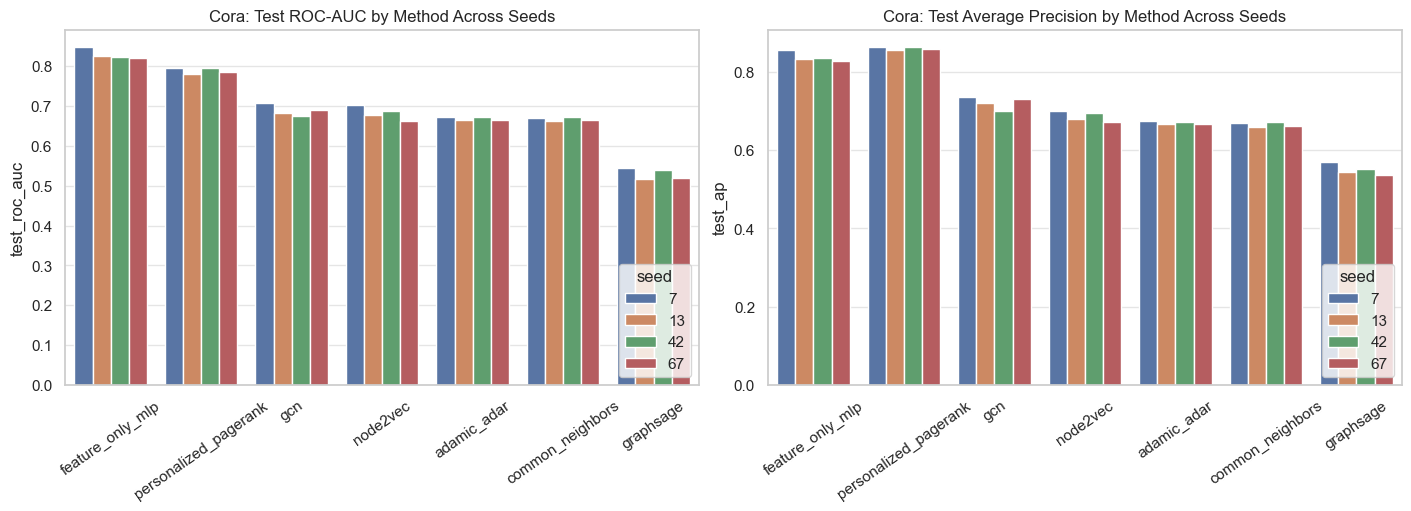

In [10]:
plot_cora_df = cora_all_seeds_df.copy()
plot_cora_df["seed"] = plot_cora_df["seed"].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

sns.barplot(
    data=plot_cora_df,
    x="method",
    y="test_roc_auc",
    hue="seed",
    ax=axes[0],
)
axes[0].set_title("Cora: Test ROC-AUC by Method Across Seeds")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=35)

sns.barplot(
    data=plot_cora_df,
    x="method",
    y="test_ap",
    hue="seed",
    ax=axes[1],
)
axes[1].set_title("Cora: Test Average Precision by Method Across Seeds")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=35)

for axis in axes:
    axis.legend(title="seed", loc="lower right")

plt.show()

## 4. Configuration Snapshot

Use this table to trace any shown metric back to the saved JSON payload and parameter set.

In [11]:
config_snapshot = all_results_df[["dataset", "seed", "method", "params", "result_path"]].copy()
config_snapshot

,dataset,seed,method,params,result_path
0,Cora,7,feature_only_mlp,"{'batch_size': 1024, 'best_epoch': 100, 'dropout': 0.2, 'epochs': 100, 'feature_mode': 'hadamard_abs_diff', 'hidden_...",results\cora\feature_only_mlp_seed7.json
1,Cora,7,personalized_pagerank,"{'alpha': 0.85, 'split_seed': 7, 'train_graph_edges': 7392}",results\cora\personalized_pagerank_seed7.json
2,Cora,7,gcn,"{'best_epoch': 9, 'decoder_hidden_dim': 64, 'dropout': 0.2, 'epochs': 50, 'hidden_dim': 64, 'learning_rate': 0.01, '...",results\cora\gcn_seed7.json
3,Cora,7,node2vec,"{'batch_size': 512, 'classifier_c': 1.0, 'context_window': 5, 'embedding_dim': 64, 'epochs': 3, 'learning_rate': 0.0...",results\cora\node2vec_seed7.json
4,Cora,7,adamic_adar,"{'split_seed': 7, 'train_graph_edges': 7392}",results\cora\adamic_adar_seed7.json
5,Cora,7,common_neighbors,"{'split_seed': 7, 'train_graph_edges': 7392}",results\cora\common_neighbors_seed7.json
6,Cora,7,graphsage,"{'best_epoch': 4, 'decoder_hidden_dim': 64, 'dropout': 0.2, 'epochs': 50, 'hidden_dim': 64, 'learning_rate': 0.01, '...",results\cora\graphsage_seed7.json
7,Cora,13,feature_only_mlp,"{'batch_size': 1024, 'best_epoch': 100, 'dropout': 0.2, 'epochs': 100, 'feature_mode': 'hadamard_abs_diff', 'hidden_...",results\cora\feature_only_mlp_seed13.json
8,Cora,13,personalized_pagerank,"{'alpha': 0.85, 'split_seed': 13, 'train_graph_edges': 7392}",results\cora\personalized_pagerank_seed13.json
9,Cora,13,gcn,"{'best_epoch': 8, 'decoder_hidden_dim': 64, 'dropout': 0.2, 'epochs': 50, 'hidden_dim': 64, 'learning_rate': 0.01, '...",results\cora\gcn_seed13.json
